In [1]:
!wget -q https://github.com/Lab41/VOiCES-subset/raw/master/Lab41-SRI-VOiCES_ref_SUBSET.csv
!wget -q https://github.com/Lab41/VOiCES-subset/raw/master/Lab41-SRI-VOiCES-speaker-gender-dataset_SUBSET.csv
!wget -q https://github.com/Lab41/VOiCES-subset/raw/master/VOiCES_90deg_features.csv

import pandas as pd

ref = pd.read_csv("Lab41-SRI-VOiCES_ref_SUBSET.csv")
print("Reference shape:", ref.shape)
print("Columns:", ref.columns.tolist())
print(ref.head(10).to_string())

Reference shape: (1500, 2)
Columns: ['fileName', 'trnscrpt']
                                                              fileName                                                                                                                                                                                                                                                                                                               trnscrpt
0  Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg0011-mc07-stu-beh-dg090                                                                                                       a wink from mister lord must have been intended to convey a great deal because owing to the defect in his eyes it required no little exertion and even then could not be considered as a really first class wink
1  Lab41-SRI-VOiCES-rm1-none-sp3549-ch173591-sg0001-mc03-stu-mid-dg090                                                                                                         

In [2]:
ref["noise"]   = ref["fileName"].str.extract(r"-(musi|none|babb|tele)-")[0]
ref["room"]    = ref["fileName"].str.extract(r"-(rm\d)-")[0]
ref["speaker"] = ref["fileName"].str.extract(r"-(sp\d+)-")[0]
ref["chapter"] = ref["fileName"].str.extract(r"-(ch\d+)-")[0]

print(ref["noise"].value_counts(dropna=False))
print(ref["room"].value_counts(dropna=False))
print("speakers:", ref["speaker"].nunique(), "| chapters:", ref["chapter"].nunique())

noise
none    383
babb    380
tele    377
musi    360
Name: count, dtype: int64
room
rm2    755
rm1    745
Name: count, dtype: int64
speakers: 104 | chapters: 122


In [3]:
!wget -q https://github.com/Lab41/VOiCES-subset/raw/master/VOiCES_90_1.tar
!tar -tf VOiCES_90_1.tar | head -20

Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg0019-mc01-stu-clo-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg0005-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-tele-sp5386-ch004145-sg0031-mc07-stu-beh-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg0012-mc03-stu-mid-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm1-none-sp7498-ch099124-sg0015-mc07-stu-beh-dg090.wav
Users/mbarrios/Documents/VOICES/IQT_Github_repo/90deg_50-50/part_1/Lab41-SRI-VOiCES-rm2-none-sp088

In [4]:
%%bash
for i in 1 2 3 4 5 6 7 8; do
  wget -q https://github.com/Lab41/VOiCES-subset/raw/master/VOiCES_90_$i.tar
done
ls -lh VOiCES_90_*.tar

-rw-r--r-- 1 root root 46M Nov  7 21:49 VOiCES_90_1.tar
-rw-r--r-- 1 root root 46M Nov  7 21:52 VOiCES_90_2.tar
-rw-r--r-- 1 root root 46M Nov  7 21:52 VOiCES_90_3.tar
-rw-r--r-- 1 root root 46M Nov  7 21:52 VOiCES_90_4.tar
-rw-r--r-- 1 root root 45M Nov  7 21:52 VOiCES_90_5.tar
-rw-r--r-- 1 root root 44M Nov  7 21:52 VOiCES_90_6.tar
-rw-r--r-- 1 root root 45M Nov  7 21:52 VOiCES_90_7.tar
-rw-r--r-- 1 root root 47M Nov  7 21:52 VOiCES_90_8.tar


In [5]:
import tarfile, os

os.makedirs("wav", exist_ok=True)
for i in range(1, 9):
    with tarfile.open(f"VOiCES_90_{i}.tar") as tf:
        for m in tf.getmembers():
            if m.isfile() and m.name.endswith(".wav"):
                m.name = os.path.basename(m.name)   # إزالة المسارات الداخلية
                tf.extract(m, "wav")

wavs = set(os.listdir("wav"))
expected = set(ref["fileName"] + ".wav")

print("WAV files extracted:", len(wavs))
print("In reference but missing from WAV:", len(expected - wavs))
print("WAV files not in reference:", len(wavs - expected))

/tmp/ipykernel_2800/2332964586.py:9: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extract(m, "wav")


WAV files extracted: 909
In reference but missing from WAV: 592
WAV files not in reference: 1


In [6]:
import tarfile, collections, os, difflib

names = []
for i in range(1, 9):
    with tarfile.open(f"VOiCES_90_{i}.tar") as tf:
        wav_members = [m for m in tf.getmembers() if m.isfile() and m.name.endswith(".wav")]
        print(f"VOiCES_90_{i}.tar: {len(wav_members)} wav files")
        names += [os.path.basename(m.name) for m in wav_members]

counts = collections.Counter(names)
print("\ntotal wav members in all tars:", len(names))
print("unique wav names:", len(counts))
print("names appearing more than once:", sum(1 for c in counts.values() if c > 1))

wavs = set(os.listdir("wav"))
expected = set(ref["fileName"] + ".wav")

extra = wavs - expected
print("\nextra file(s) not in reference:", extra)
for e in extra:
    print("closest reference names:", difflib.get_close_matches(e, expected, n=3))

missing = sorted(expected - wavs)
print("\nmissing count:", len(missing))
print("sample missing:", missing[:5])

VOiCES_90_1.tar: 114 wav files
VOiCES_90_2.tar: 113 wav files
VOiCES_90_3.tar: 113 wav files
VOiCES_90_4.tar: 113 wav files
VOiCES_90_5.tar: 113 wav files
VOiCES_90_6.tar: 113 wav files
VOiCES_90_7.tar: 115 wav files
VOiCES_90_8.tar: 115 wav files

total wav members in all tars: 909
unique wav names: 909
names appearing more than once: 0

extra file(s) not in reference: {'._Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav'}
closest reference names: ['Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav', 'Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc03-stu-mid-dg090.wav', 'Lab41-SRI-VOiCES-rm2-musi-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav']

missing count: 592
sample missing: ['Lab41-SRI-VOiCES-rm1-babb-sp0150-ch126107-sg0026-mc05-stu-far-dg090.wav', 'Lab41-SRI-VOiCES-rm1-babb-sp0188-ch135249-sg0020-mc03-stu-mid-dg090.wav', 'Lab41-SRI-VOiCES-rm1-babb-sp0209-ch004733-sg0027-mc07-stu-beh-dg090.wav', 'Lab41-SRI-VOiCES-rm1-babb-sp0250-ch

In [7]:
import os

os.remove("wav/._Lab41-SRI-VOiCES-rm2-tele-sp8118-ch268287-sg0020-mc05-stu-far-dg090.wav")

present = set(os.listdir("wav"))
ref["present"] = (ref["fileName"] + ".wav").isin(present)

print("present:", ref["present"].sum(), "of", len(ref))
print("\nBy noise:")
print(ref.groupby("noise")["present"].agg(["sum", "count"]))
print("\nBy room:")
print(ref.groupby("room")["present"].agg(["sum", "count"]))
print("\nBy speaker count (speakers with at least one recording):",
      ref.loc[ref["present"], "speaker"].nunique())

present: 908 of 1500

By noise:
       sum  count
noise            
babb   228    380
musi   231    360
none   227    383
tele   222    377

By room:
      sum  count
room            
rm1   446    745
rm2   462    755

By speaker count (speakers with at least one recording): 104


In [9]:
import soundfile as sf

sample = "wav/" + ref.loc[ref["present"], "fileName"].iloc[0] + ".wav"
info = sf.info(sample)
print("sample rate:", info.samplerate, "| channels:", info.channels)
print("duration (s):", round(info.duration, 2))

present = ref[ref["present"]]
print("unique chapters (groups):", present["chapter"].nunique())
print("unique transcripts:", present["trnscrpt"].nunique())
print("recordings per chapter:", present.groupby("chapter").size().value_counts().to_dict())

sample rate: 16000 | channels: 1
duration (s): 16.48
unique chapters (groups): 122
unique transcripts: 128
recordings per chapter: {6: 21, 10: 15, 5: 15, 8: 12, 9: 11, 11: 11, 4: 10, 3: 7, 12: 6, 2: 6, 13: 4, 7: 3, 23: 1}


In [10]:
import numpy as np
import soundfile as sf
import torch
import torchaudio

present = ref[ref["present"]].reset_index(drop=True)

mfcc = torchaudio.transforms.MFCC(
    sample_rate=16000,
    n_mfcc=20,
    melkwargs={"n_fft": 512, "hop_length": 160, "n_mels": 40},
)

X, y, groups = [], [], []
for _, row in present.iterrows():
    wav, sr = sf.read("wav/" + row["fileName"] + ".wav", dtype="float32")
    feat = mfcc(torch.tensor(wav).unsqueeze(0)).squeeze(0)   # (20, frames)
    stat = torch.cat([feat.mean(dim=1), feat.std(dim=1)]).numpy()  # (40,)
    X.append(stat)
    y.append(row["noise"])
    groups.append(row["chapter"])

X = np.stack(X)
y = np.array(y)
groups = np.array(groups)
np.savez("features_event.npz", X=X, y=y, groups=groups)

print("X shape:", X.shape)
print("labels:", dict(zip(*np.unique(y, return_counts=True))))
print("groups (chapters):", len(np.unique(groups)))

X shape: (908, 40)
labels: {np.str_('babb'): np.int64(228), np.str_('musi'): np.int64(231), np.str_('none'): np.int64(227), np.str_('tele'): np.int64(222)}
groups (chapters): 122


In [11]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

gkf = GroupKFold(n_splits=5)

def evaluate(model):
    accs, f1s = [], []
    for tr, te in gkf.split(X, y, groups):
        m = clone(model)
        m.fit(X[tr], y[tr])
        pred = m.predict(X[te])
        accs.append(accuracy_score(y[te], pred))
        f1s.append(f1_score(y[te], pred, average="macro"))
    return np.mean(accs), np.std(accs), np.mean(f1s), np.std(f1s)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=0),
}

event_results = {}
for name, model in models.items():
    event_results[name] = evaluate(model)

print(f"{'Classifier':<22}{'Accuracy':>20}{'Macro-F1':>20}")
for name, (am, asd, fm, fsd) in event_results.items():
    print(f"{name:<22}{am:>12.3f} ± {asd:.3f}{fm:>12.3f} ± {fsd:.3f}")

Classifier                        Accuracy            Macro-F1
Logistic Regression          0.657 ± 0.024       0.652 ± 0.023
SVM (RBF)                    0.754 ± 0.027       0.749 ± 0.030
Random Forest                0.703 ± 0.024       0.691 ± 0.029


In [12]:
import torch.nn as nn

class EventMLP(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(40, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, n_classes),
        )
    def forward(self, x):
        return self.net(x)

classes = np.unique(y)
class_to_idx = {c: i for i, c in enumerate(classes)}
y_idx = np.array([class_to_idx[c] for c in y])

def mlp_fit_predict(Xtr, ytr, Xte, epochs=200, lr=1e-3):
    torch.manual_seed(0)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8
    Xtr_t = torch.tensor((Xtr - mu) / sd, dtype=torch.float32)
    Xte_t = torch.tensor((Xte - mu) / sd, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.long)

    model = EventMLP(len(classes))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss_fn(model(Xtr_t), ytr_t).backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte_t).argmax(dim=1).numpy()

accs, f1s = [], []
for tr, te in gkf.split(X, y_idx, groups):
    pred = mlp_fit_predict(X[tr], y_idx[tr], X[te])
    accs.append(accuracy_score(y_idx[te], pred))
    f1s.append(f1_score(y_idx[te], pred, average="macro"))

event_results["MLP (PyTorch)"] = (np.mean(accs), np.std(accs), np.mean(f1s), np.std(f1s))
am, asd, fm, fsd = event_results["MLP (PyTorch)"]
print(f"{'MLP (PyTorch)':<22}{am:>12.3f} ± {asd:.3f}{fm:>12.3f} ± {fsd:.3f}")

MLP (PyTorch)                0.730 ± 0.013       0.725 ± 0.010


[[196   8   1  23]
 [ 14 189  14  14]
 [  6  19 175  27]
 [ 27  27  43 125]]


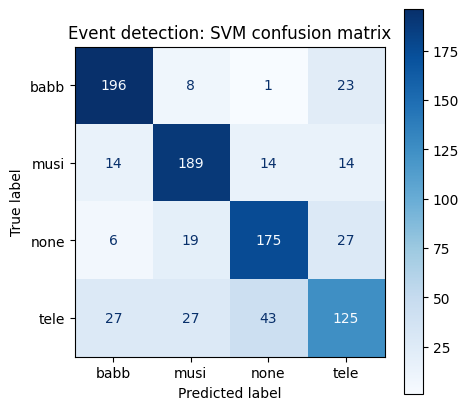

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict

svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0))
y_pred = np.empty_like(y)
for tr, te in gkf.split(X, y, groups):
    m = clone(svm).fit(X[tr], y[tr])
    y_pred[te] = m.predict(X[te])

labels = np.unique(y)
cm = confusion_matrix(y, y_pred, labels=labels)
print(cm)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Event detection: SVM confusion matrix")
plt.show()

In [14]:
import torchaudio
bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H
print("sample rate:", bundle.sample_rate)
print("labels:", bundle.get_labels())
model = bundle.get_model()
print("model loaded:", type(model).__name__)

sample rate: 16000
labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')
Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960_asr_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960_asr_ls960.pth


100%|██████████| 360M/360M [00:01<00:00, 224MB/s]


model loaded: Wav2Vec2Model


transcript: WHICH WOULD MAKE ME REVERE ITS POSSESSOR WERE HE THE LOWLIEST MAN IN YOUR LEGIONS ALLOW ME NOBLEST OF SCOTS TO PLEAD ONE WORD IN VINDICATION OF HIM TO WHOM MY ALLEGIANCE IS PLEDGED HAD HE COME HITHER CONDUCTED BY WAR ALONE WHAT WOULD EDWARD HAVE BEEN WORSE THAN ANY OTHER CONQUEROR
duration: 16.48 s
speech frames: 273 = 5.46 s


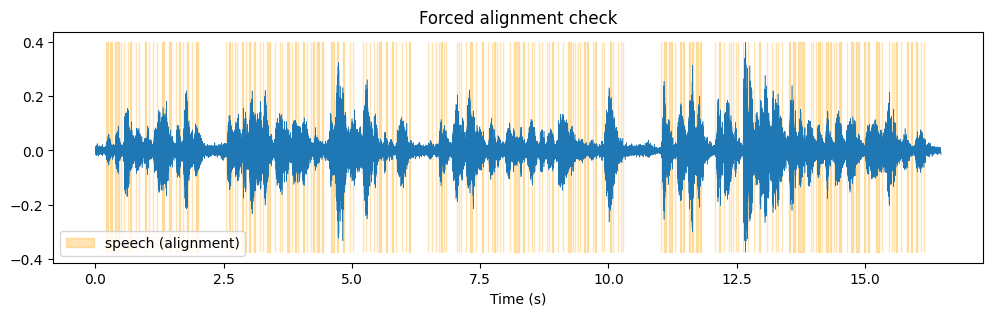

In [15]:
import re
import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
import torchaudio.functional as taF
import matplotlib.pyplot as plt

bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H
asr = bundle.get_model().eval()
labels = bundle.get_labels()
dic = {c: i for i, c in enumerate(labels)}
BLANK, SPACE = dic["-"], dic["|"]

def norm_text(t):
    t = re.sub(r"[^A-Za-z' ]", " ", str(t)).upper()
    return " ".join(t.split())

def targets_from_text(t):
    return [dic[c] for c in norm_text(t).replace(" ", "|") if c in dic]

def align(path, text):
    wav, sr = sf.read(path, dtype="float32")
    x = torch.tensor(wav).unsqueeze(0)
    with torch.inference_mode():
        emission, _ = asr(x)
    log_probs = F.log_softmax(emission, dim=-1)
    tgt = torch.tensor([targets_from_text(text)], dtype=torch.int32)
    ali, scores = taF.forced_align(log_probs, tgt, blank=BLANK)
    spans = taF.merge_tokens(ali[0], scores[0].exp())
    n_frames = emission.shape[1]
    frame_sec = len(wav) / n_frames / sr
    mask = np.zeros(n_frames, dtype=np.int8)
    for s in spans:
        if s.token != SPACE:          # نستثني الفاصل بين الكلمات
            mask[s.start:s.end] = 1
    return mask, frame_sec, wav, sr

row = present.iloc[0]
path = "wav/" + row["fileName"] + ".wav"
mask, frame_sec, wav, sr = align(path, row["trnscrpt"])

print("transcript:", norm_text(row["trnscrpt"]))
print("duration:", round(len(wav) / sr, 2), "s")
print("speech frames:", int(mask.sum()), "=", round(mask.sum() * frame_sec, 2), "s")

t_frames = np.arange(len(mask)) * frame_sec
t_wav = np.arange(len(wav)) / sr
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_wav, wav, linewidth=0.4)
ax.fill_between(t_frames, wav.min(), wav.max(), where=mask.astype(bool),
                color="orange", alpha=0.3, step="post", label="speech (alignment)")
ax.set_xlabel("Time (s)")
ax.set_title("Forced alignment check")
ax.legend()
plt.show()

transcript: WHICH WOULD MAKE ME REVERE ITS POSSESSOR WERE HE THE LOWLIEST MAN IN YOUR LEGIONS ALLOW ME NOBLEST OF SCOTS TO PLEAD ONE ...
duration: 16.48 s
words: 52
speech frames: 520 = 10.4 s


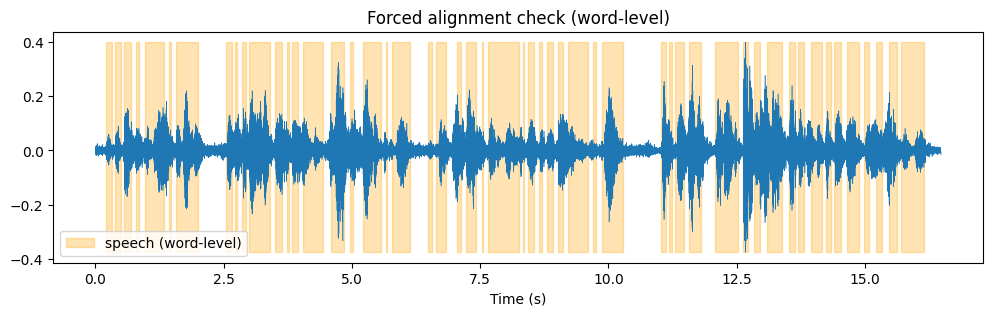

In [16]:
import re
import numpy as np
import soundfile as sf
import torch
import torch.nn.functional as F
import torchaudio
import torchaudio.functional as taF
import matplotlib.pyplot as plt

bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H
asr = bundle.get_model().eval()
labels = bundle.get_labels()
dic = {c: i for i, c in enumerate(labels)}
BLANK, SPACE = dic["-"], dic["|"]

def norm_text(t):
    t = re.sub(r"[^A-Za-z' ]", " ", str(t)).upper()
    return " ".join(t.split())

def targets_from_text(t):
    return [dic[c] for c in norm_text(t).replace(" ", "|") if c in dic]

def word_spans(spans):
    words, cur = [], None
    for s in spans:
        if s.token == SPACE:
            if cur is not None:
                words.append(cur)
                cur = None
        else:
            if cur is None:
                cur = [s.start, s.end]
            else:
                cur[1] = s.end
    if cur is not None:
        words.append(cur)
    return words

def align(path, text):
    wav, sr = sf.read(path, dtype="float32")
    x = torch.tensor(wav).unsqueeze(0)
    with torch.inference_mode():
        emission, _ = asr(x)
    log_probs = F.log_softmax(emission, dim=-1)
    tgt = torch.tensor([targets_from_text(text)], dtype=torch.int32)
    ali, scores = taF.forced_align(log_probs, tgt, blank=BLANK)
    spans = taF.merge_tokens(ali[0], scores[0].exp())
    n_frames = emission.shape[1]
    frame_sec = len(wav) / n_frames / sr
    mask = np.zeros(n_frames, dtype=np.int8)
    words = word_spans(spans)
    for w0, w1 in words:
        mask[w0:w1] = 1
    return mask, frame_sec, wav, sr, len(words)

row = present.iloc[0]
path = "wav/" + row["fileName"] + ".wav"
mask, frame_sec, wav, sr, n_words = align(path, row["trnscrpt"])

print("transcript:", norm_text(row["trnscrpt"])[:120], "...")
print("duration:", round(len(wav) / sr, 2), "s")
print("words:", n_words)
print("speech frames:", int(mask.sum()), "=", round(mask.sum() * frame_sec, 2), "s")

t_frames = np.arange(len(mask)) * frame_sec
t_wav = np.arange(len(wav)) / sr
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_wav, wav, linewidth=0.4)
ax.fill_between(t_frames, wav.min(), wav.max(), where=mask.astype(bool),
                color="orange", alpha=0.3, step="post", label="speech (word-level)")
ax.set_xlabel("Time (s)")
ax.set_title("Forced alignment check (word-level)")
ax.legend()
plt.show()

In [18]:
MARGIN_SEC = 0.03

mask2, frame_sec, wav, sr, n_words = align_with_margin(path, row["trnscrpt"])
print("speech frames with margin:", int(mask2.sum()), "=", round(mask2.sum() * frame_sec, 2), "s")
print("speech ratio:", round(mask2.sum() / len(mask2), 3))

speech frames with margin: 624 = 12.48 s
speech ratio: 0.757


In [19]:
import pickle, time

masks, errors = {}, {}
t0 = time.time()

for k, (_, r) in enumerate(present.iterrows()):
    fn = r["fileName"]
    try:
        m, fs, _, _, nw = align_with_margin("wav/" + fn + ".wav", r["trnscrpt"])
        masks[fn] = {"mask": m, "frame_sec": fs, "n_words": nw}
    except Exception as e:
        errors[fn] = repr(e)
    if (k + 1) % 100 == 0:
        print(f"{k+1}/{len(present)} done, {time.time()-t0:.0f}s elapsed")
        with open("vad_masks.pkl", "wb") as f:
            pickle.dump(masks, f)

with open("vad_masks.pkl", "wb") as f:
    pickle.dump(masks, f)

print("ok:", len(masks), "| errors:", len(errors), "| time:", round(time.time() - t0), "s")
for k, v in list(errors.items())[:5]:
    print(k, v)

100/908 done, 509s elapsed
200/908 done, 1020s elapsed
300/908 done, 1528s elapsed
400/908 done, 2039s elapsed
500/908 done, 2557s elapsed
600/908 done, 3076s elapsed
700/908 done, 3601s elapsed
800/908 done, 4117s elapsed
900/908 done, 4648s elapsed
ok: 908 | errors: 0 | time: 4683 s


In [20]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

def energy_vad(wav, n_frames, offset_db=10.0):
    chunks = np.array_split(wav, n_frames)
    e = np.array([np.mean(c.astype(np.float64) ** 2) if len(c) else 0.0 for c in chunks])
    db = 10 * np.log10(e + 1e-10)
    floor = np.percentile(db, 10)
    return (db > floor + offset_db).astype(np.int8)

y_true_all, y_pred_all, per_file_acc = [], [], []
for fn, info in masks.items():
    wav, sr = sf.read("wav/" + fn + ".wav", dtype="float32")
    ref_m = info["mask"]
    pred = energy_vad(wav, len(ref_m))
    y_true_all.append(ref_m)
    y_pred_all.append(pred)
    per_file_acc.append(accuracy_score(ref_m, pred))

yt = np.concatenate(y_true_all)
yp = np.concatenate(y_pred_all)

p, r, f, _ = precision_recall_fscore_support(yt, yp, average="binary", pos_label=1)
print(f"Frames evaluated: {len(yt)}")
print(f"Reference speech ratio: {yt.mean():.3f}")
print(f"Energy VAD frame accuracy: {accuracy_score(yt, yp):.3f}")
print(f"Speech precision: {p:.3f} | recall: {r:.3f} | F1: {f:.3f}")
print(f"Per-file accuracy: {np.mean(per_file_acc):.3f} ± {np.std(per_file_acc):.3f}")

Frames evaluated: 705867
Reference speech ratio: 0.666
Energy VAD frame accuracy: 0.753
Speech precision: 0.851 | recall: 0.762 | F1: 0.804
Per-file accuracy: 0.752 ± 0.097


In [21]:
import numpy as np, soundfile as sf, torch, torchaudio
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# MFCC بنفس معدل الإطارات الزمنية لقناع المحاذاة (20 ms)
mfcc_t = torchaudio.transforms.MFCC(
    sample_rate=16000, n_mfcc=20,
    melkwargs={"n_fft": 512, "hop_length": 320, "n_mels": 40},
)

def frame_features(wav, n_target, ctx=2):
    m = mfcc_t(torch.tensor(wav).unsqueeze(0)).squeeze(0)          # (20, T)
    m = F.interpolate(m.unsqueeze(0), size=n_target, mode="linear",
                      align_corners=False).squeeze(0).T.numpy()    # (n_target, 20)
    padded = np.pad(m, ((ctx, ctx), (0, 0)), mode="edge")
    stacked = np.concatenate([padded[i:i + n_target] for i in range(2 * ctx + 1)], axis=1)
    return stacked.astype(np.float32)                              # (n_target, 100)

chapter_of = dict(zip(present["fileName"], present["chapter"]))

Xs, ys, gs, es = [], [], [], []
for fn, info in masks.items():
    wav, sr = sf.read("wav/" + fn + ".wav", dtype="float32")
    y_f = info["mask"]
    Xs.append(frame_features(wav, len(y_f)))
    ys.append(y_f)
    gs.append(np.full(len(y_f), chapter_of[fn]))
    es.append(energy_vad(wav, len(y_f)))

X = np.vstack(Xs); y = np.concatenate(ys)
g = np.concatenate(gs); e = np.concatenate(es)
print("frames:", X.shape[0], "| features:", X.shape[1], "| speech ratio:", round(y.mean(), 3))

gkf = GroupKFold(n_splits=5)
rng = np.random.default_rng(0)
rows = {"Logistic Regression": [], "Energy baseline": []}

for tr, te in gkf.split(X, y, g):
    sub = rng.choice(tr, size=min(100_000, len(tr)), replace=False)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    clf.fit(X[sub], y[sub])
    for name, pred in [("Logistic Regression", clf.predict(X[te])),
                       ("Energy baseline", e[te])]:
        p, r, f, _ = precision_recall_fscore_support(y[te], pred, average="binary", pos_label=1)
        rows[name].append((accuracy_score(y[te], pred), p, r, f))

print(f"{'Method':<22}{'Accuracy':>12}{'Precision':>12}{'Recall':>12}{'F1':>12}")
for name, arr in rows.items():
    a = np.array(arr)
    m, s = a.mean(0), a.std(0)
    print(f"{name:<22}" + "".join(f"{m[i]:>7.3f}±{s[i]:.3f}" for i in range(4)))

frames: 705867 | features: 100 | speech ratio: 0.666
Method                    Accuracy   Precision      Recall          F1
Logistic Regression     0.829±0.002  0.836±0.017  0.925±0.020  0.878±0.000
Energy baseline         0.753±0.010  0.851±0.011  0.762±0.020  0.804±0.008


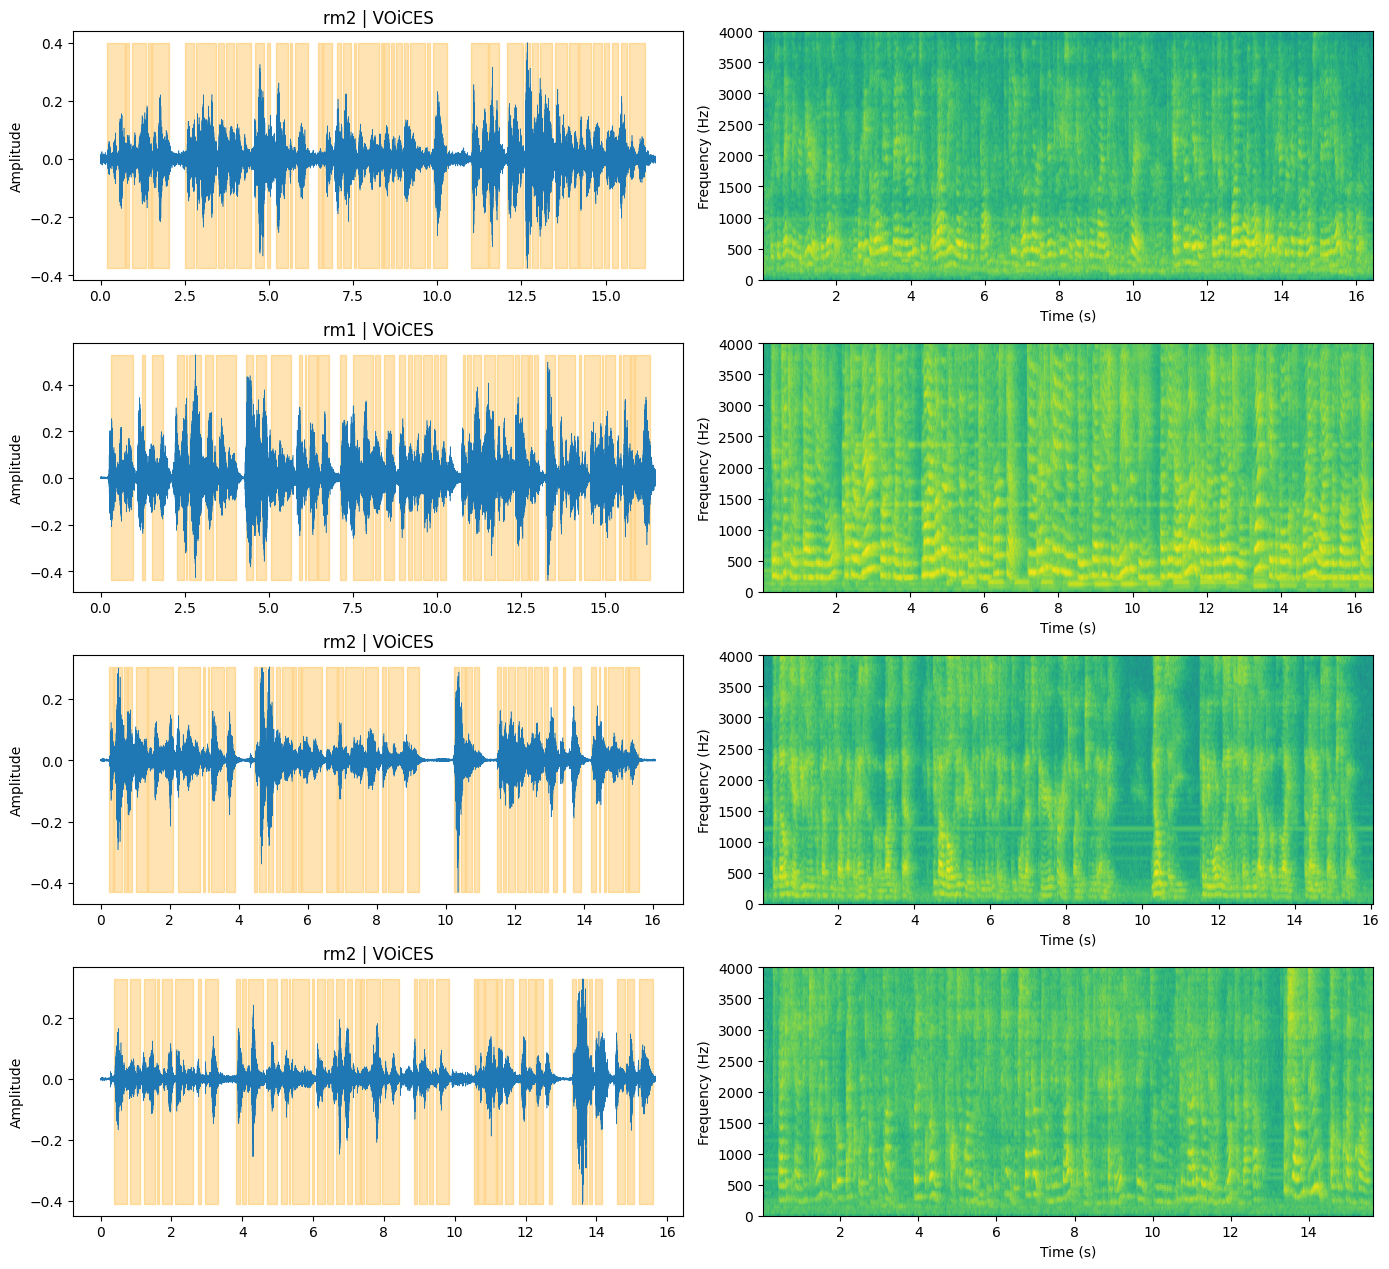

saved: vad_examples.png


In [22]:
import matplotlib.pyplot as plt

def plot_vad_example(fn, ax_wave, ax_spec):
    wav, sr = sf.read("wav/" + fn + ".wav", dtype="float32")
    info = masks[fn]
    m = info["mask"]
    fs = info["frame_sec"]
    t = np.arange(len(wav)) / sr
    tf = np.arange(len(m)) * fs

    ax_wave.plot(t, wav, linewidth=0.4, color="tab:blue")
    ax_wave.fill_between(tf, wav.min(), wav.max(), where=m.astype(bool),
                         color="orange", alpha=0.3, step="post")
    ax_wave.set_title(f"{fn.split('-')[3]} | {fn.split('-')[2]}")
    ax_wave.set_ylabel("Amplitude")

    ax_spec.specgram(wav, Fs=sr, NFFT=512, noverlap=384, cmap="viridis")
    ax_spec.set_ylim(0, 4000)
    ax_spec.set_ylabel("Frequency (Hz)")
    ax_spec.set_xlabel("Time (s)")

# ننتقي تسجيلاً من كل نوع ضوضاء
examples = []
for noise in ["babb", "musi", "none", "tele"]:
    fns = [f for f in masks if f"-{noise}-" in f]
    examples.append(fns[0])

fig, axes = plt.subplots(len(examples), 2, figsize=(14, 3.2 * len(examples)))
for i, fn in enumerate(examples):
    plot_vad_example(fn, axes[i, 0], axes[i, 1])
plt.tight_layout()
plt.savefig("vad_examples.png", dpi=150)
plt.show()
print("saved: vad_examples.png")